In [1]:
#Import Libraries
import pandas as pd
import seaborn as sns
import statsmodels.api as sm
import statsmodels.stats.api as sms
from statsmodels.stats.outliers_influence import variance_inflation_factor as vif 
from statsmodels.compat import lzip
import statsmodels.stats.diagnostic as smd
import matplotlib.pyplot as plt
import numpy as np

In [41]:
#import the data
df = pd.read_csv('car_data.csv')
df.head()

,year,selling_price,km_driven,fuel,seller_type,transmission,engine_cc,max_power,seats
0,2014,450000,145500,Diesel,Individual,Manual,1248,74,5
1,2014,370000,120000,Diesel,Individual,Manual,1498,104,5
2,2006,158000,140000,Petrol,Individual,Manual,1497,78,0
3,2010,225000,127000,Diesel,Individual,Manual,1396,90,5
4,2007,130000,120000,Petrol,Individual,Manual,1298,88,0


Assumption 1: Checking for outliers

In [42]:
#check for outliers
pd.options.display.float_format = '{:.0f}'.format #set the decimals (0f = 0 decimals)
df.describe()

,year,selling_price,km_driven,engine_cc,max_power,seats
count,7904,7904,7904,7904,7904,7904
mean,2014,648590,68727,1459,92,5
std,4,806881,47985,504,36,1
min,1994,29999,1,624,33,0
25%,2012,270000,35000,1197,68,5
50%,2015,450000,60000,1248,82,5
75%,2017,690000,95275,1582,102,5
max,2020,7200000,577414,3604,282,14


In [43]:
#There doesn't seem to be much strange going on, except that the variable seats has a minumum of 0. 
#This could be a data mistake, or it could be a placeholder for unknown values
#Either way, we need to remove it

df = df[df['seats']>0] #this selects only the rows where seats is more than 0
df.describe() #Use this to double check that it went correctly

,year,selling_price,km_driven,engine_cc,max_power,seats
count,7563,7563,7563,7563,7563,7563
mean,2014,668027,67223,1456,92,5
std,4,818135,47629,509,36,1
min,1994,29999,1,624,33,2
25%,2012,290000,31800,1197,68,5
50%,2015,475000,60000,1248,82,5
75%,2017,700000,90000,1582,102,5
max,2020,7200000,577414,3604,282,14


Assumption 2: checking for multicollinearity

In [44]:
#remove missings and create dummy variables
df = df.dropna()
df = pd.get_dummies(df, drop_first=True, dtype='int')

In [45]:
#check for multicollinearity
X = df.drop('selling_price', axis=1) #remove the dependent variable
X = sm.add_constant(X) #DON'T FORGET THIS PART

#Create a dataframe that contains the VIF values
VIF_data = pd.DataFrame() #create a pandas dataframe
VIF_data["variable"] = X.columns #create a variable that simply lists the names of the variables you picked
VIF_data["VIF"] = [vif(X,i) 
                   for i in range(len(X.columns))] #a loop that creates vif values for each variable and then puts it in the VIF column
print(VIF_data) #print the results

                        variable    VIF
0                          const 440585
1                           year      1
2                      km_driven      2
3                      engine_cc      5
4                      max_power      3
5                          seats      2
6                    fuel_Diesel     37
7                       fuel_LPG      2
8                    fuel_Petrol     37
9         seller_type_Individual      1
10  seller_type_Trustmark_Dealer      1
11           transmission_Manual      2


There is very high multicolinearity between Diesel and Petrol. This is probably because the large majority of cars (almost 99%) is petrol or diesel. This means that the petrol and diesel dummy variables are almost opposites of each other and thus correlate very highly. Furthermore, the fuel type CNG was removed when we removed the missing values, so that is not the reference category. The easiest solution is to remove the Diesel variable so that that becomes the reference category.

In [46]:
#drop the fuel_Diesel variable
df = df.drop('fuel_Diesel', axis=1) 


Assumption 3: Observations are independent. 
This not is time series or panel data so there is no autocorrelation. There is also no indication that the observations are nested in any of the other variables. Therefore, we can assume that this assumption has been met. 

Assumption 4: Relationships are linear

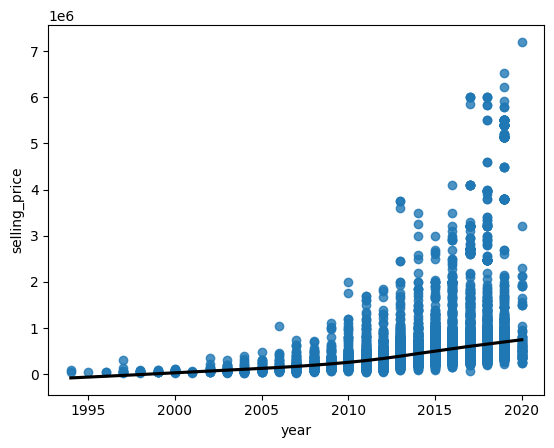

In [47]:
#Let's create a bunch of scatterplots with lowess functions
graph1 = sns.regplot(x = df['year'], y = df['selling_price'], lowess = True,line_kws={"color": "black"})

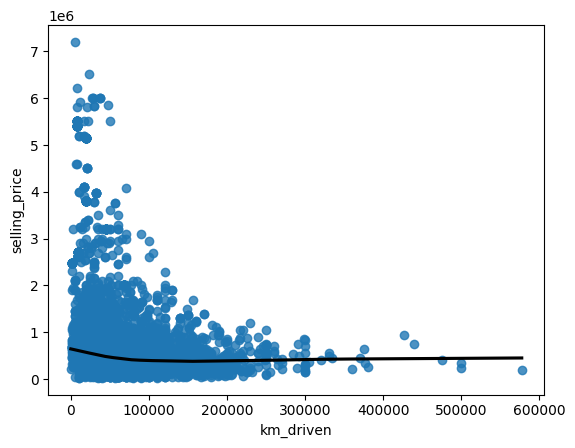

In [48]:
graph2 = sns.regplot(x = df['km_driven'], y = df['selling_price'], lowess = True,line_kws={"color": "black"})

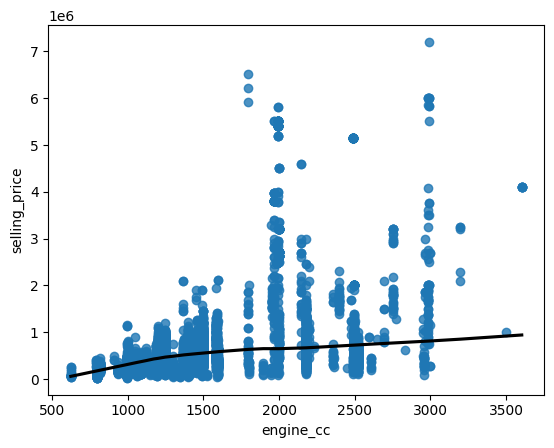

In [49]:
graph3 = sns.regplot(x = df['engine_cc'], y = df['selling_price'], lowess = True,line_kws={"color": "black"})

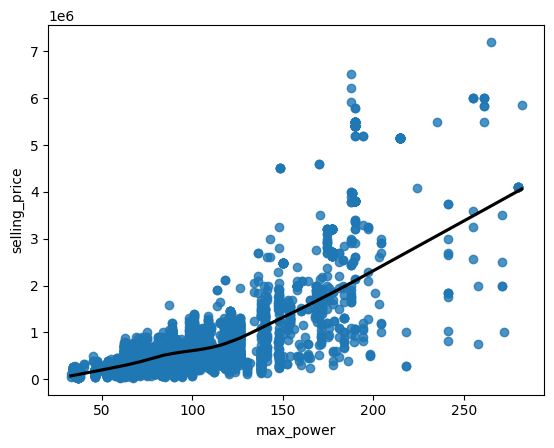

In [50]:
graph2 = sns.regplot(x = df['max_power'], y = df['selling_price'], lowess = True,line_kws={"color": "black"})

c:\Users\Tijmen\anaconda3\envs\env2526\Lib\site-packages\statsmodels\nonparametric\smoothers_lowess.py:226: RuntimeWarning: invalid value encountered in divide
  res, _ = _lowess(y, x, x, np.ones_like(x),


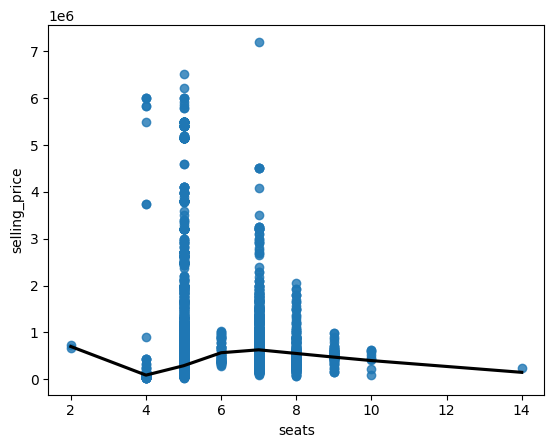

In [51]:
graph2 = sns.regplot(x = df['seats'], y = df['selling_price'], lowess = True,line_kws={"color": "black"})

It seams year has a slight exponential relationship. Km driven a log relationship. Engine_CC, max_power, and seats are more or less linear.

In [52]:
#Make the right transformations
df['logkm_driven'] = np.log(df['km_driven'])
df['year2'] = pow(df['year'],2)

Assumption 5: No heteroskedasticity

In [53]:
#First run the model we have so far
y = df['selling_price'] #select dependent variable
X = df.drop(['selling_price','km_driven'],axis=1) #drop unwanted variables
X = sm.add_constant(X) #add intercept. DON'T FORGET
model1 = sm.OLS(y,X) #create the model
results = model1.fit() #fit the model to the data
print(results.summary()) #print the results

                            OLS Regression Results                            
Dep. Variable:          selling_price   R-squared:                       0.705
Model:                            OLS   Adj. R-squared:                  0.704
Method:                 Least Squares   F-statistic:                     1638.
Date:                Wed, 08 Jul 2026   Prob (F-statistic):               0.00
Time:                        14:32:31   Log-Likelihood:            -1.0909e+05
No. Observations:                7563   AIC:                         2.182e+05
Df Residuals:                    7551   BIC:                         2.183e+05
Df Model:                          11                                         
Covariance Type:            nonrobust                                         
                                   coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------------
const           

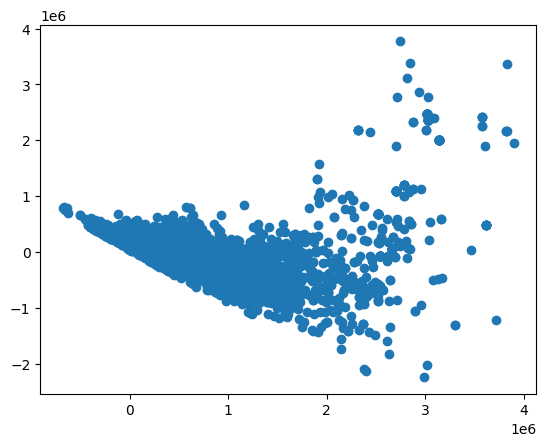

In [54]:
#Plot the residuals and fitted values
residuals = results.resid
fitted = results.fittedvalues
plt.scatter(fitted, residuals)

In [55]:
#The graph seems to show heteroskedasticity, so let's double check with the Breusch-Pagan test
bp_test = smd.het_breuschpagan(residuals, X)
labels = ['LM Statistic', 'LM-Test p-value', 'F-Statistic', 'F-Test p-value']
print(dict(zip(labels, bp_test)))

{'LM Statistic': np.float64(2470.2440924774282), 'LM-Test p-value': np.float64(0.0), 'F-Statistic': np.float64(332.965160014564), 'F-Test p-value': np.float64(0.0)}


In [56]:
#Since the p-value is smaller than 0.05, we conclude that there is heteroskedasticity and we have to use the robust estimator
y = df['selling_price'] #select dependent variable
X = df.drop(['selling_price','km_driven'],axis=1) #drop unwanted variables
X = sm.add_constant(X) #add intercept. DON'T FORGET
model1 = sm.OLS(y,X) #create the model
results = model1.fit(cov_type='HC1') #fit the model with the robust estimator
print(results.summary()) #print the results

                            OLS Regression Results                            
Dep. Variable:          selling_price   R-squared:                       0.705
Model:                            OLS   Adj. R-squared:                  0.704
Method:                 Least Squares   F-statistic:                     427.1
Date:                Wed, 08 Jul 2026   Prob (F-statistic):               0.00
Time:                        14:33:21   Log-Likelihood:            -1.0909e+05
No. Observations:                7563   AIC:                         2.182e+05
Df Residuals:                    7551   BIC:                         2.183e+05
Df Model:                          11                                         
Covariance Type:                  HC1                                         
                                   coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------------------
const           

Assumption 6: normally distributed residuals
Since the sample size is very large (7563), we don't have to check this assumption. The model above can therefore be considered to be the final model. 